
# MovieLens 10M – Recommendation System

## 1. Data Loading and Preparation

This project develops and evaluates a movie recommendation system using the MovieLens 10M dataset.

In this section, we load the movie metadata and user ratings, merge the datasets using movie IDs, and extract the year of each rating from its timestamp.

In [1]:
from pathlib import Path

data_path = Path(".")

print("Movies:", (data_path / "movies.dat").exists())
print("Ratings:", (data_path / "ratings.dat").exists())

Movies: True
Ratings: True



### 1.1 Loading the MovieLens Dataset

The MovieLens 10M dataset contains movie metadata and approximately 10 million user ratings.

Two files are loaded into separate Pandas DataFrames:

- `movies.dat`: Movie IDs, titles, and genres.
- `ratings.dat`: User IDs, movie IDs, ratings, and timestamps.

The files use `::` as their field separator.

In [2]:

import pandas as pd

# Load movie metadata
movies = pd.read_csv(
    data_path / "movies.dat",
    sep="::",
    engine="python",
    header=None,
    names=["movieId", "title", "genres"],
    encoding="latin-1"
)

# Load user ratings
ratings = pd.read_csv(
    data_path / "ratings.dat",
    sep="::",
    engine="python",
    header=None,
    names=["userId", "movieId", "rating", "timestamp"]
)

print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)

display(movies.head())
display(ratings.head())

Movies shape: (10681, 3)
Ratings shape: (10000054, 4)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,122,5.0,838985046
1,1,185,5.0,838983525
2,1,231,5.0,838983392
3,1,292,5.0,838983421
4,1,316,5.0,838983392



### 1.2 Data Merging and Year Extraction

The ratings and movies DataFrames are merged using `movieId` as the common key.

A new column, `year`, is created by converting Unix timestamps into datetime values and extracting the year of each rating.

This allows us to analyze changes in user ratings over time.

In [3]:

# Merge ratings with movie metadata
df = ratings.merge(
    movies,
    on="movieId",
    how="left",
    validate="many_to_one"
)

# Extract the year from rating timestamps
df["year"] = pd.to_datetime(
    df["timestamp"],
    unit="s",
    utc=True
).dt.year

# Inspect the merged dataset
print("Merged dataset shape:", df.shape)
print("Missing movie titles:", df["title"].isna().sum())
print("Rating years:", df["year"].min(), "-", df["year"].max())

display(df.head())


Merged dataset shape: (10000054, 7)
Missing movie titles: 0
Rating years: 1995 - 2009


,userId,movieId,rating,timestamp,title,genres,year
0,1,122,5.0,838985046,Boomerang (1992),Comedy|Romance,1996
1,1,185,5.0,838983525,"Net, The (1995)",Action|Crime|Thriller,1996
2,1,231,5.0,838983392,Dumb & Dumber (1994),Comedy,1996
3,1,292,5.0,838983421,Outbreak (1995),Action|Drama|Sci-Fi|Thriller,1996
4,1,316,5.0,838983392,Stargate (1994),Action|Adventure|Sci-Fi,1996


**Loading note:** The `::` separator requires the Python parsing engine in this implementation; loading ~10 million ratings can therefore be slower than a single-character delimiter. It remains reproducible and correct.


### 1.3 Results and Observations

The data preparation process was completed successfully.

**Dataset Summary:**
- Total movies: 10,681
- Total ratings: 10,000,054
- Merged dataset: 10,000,054 rows and 7 columns
- Missing movie titles: 0
- Rating period: 1995–2009

**Key Observations:**

The merged dataset preserves all 10,000,054 ratings, indicating that no records were lost during the merging process.

No missing movie titles were detected, confirming that every rating was successfully matched with movie metadata.

The extracted `year` column represents the year in which each rating was submitted, rather than the movie's release year.

The dataset is now ready for temporal analysis of movie genres and the development of a recommendation system.


## 2. Genres with the Largest Decline in Average Ratings

### 2.1 Objective

The objective is to identify the five movie genres with the largest decrease in average annual ratings.

For each genre, we compare its mean rating in the first year with available ratings against its mean rating in the last year with available ratings.

Since movies may belong to multiple genres, each rating is included in the analysis of every genre associated with that movie.

In [4]:

# Create a separate copy for genre analysis
genre_df = df[["movieId", "rating", "year", "genres"]].copy()

# Split multiple genres into separate lists
genre_df["genres"] = genre_df["genres"].str.split("|")

# Create one row per genre
genre_df = genre_df.explode("genres")

# Calculate average rating and number of ratings per genre and year
genre_yearly = (
    genre_df.groupby(["genres", "year"])
    .agg(
        avg_rating=("rating", "mean"),
        num_ratings=("rating", "size")
    )
    .reset_index()
)

display(genre_yearly.head(10))

,genres,year,avg_rating,num_ratings
0,(no genres listed),2004,2.750000,2
1,(no genres listed),2007,4.000000,3
2,(no genres listed),2008,4.000000,2
3,Action,1995,3.000000,1
4,Action,1996,3.440509,331387
5,Action,1997,3.539915,129587
6,Action,1998,3.440092,55068
7,Action,1999,3.447994,194594
8,Action,2000,3.472286,330156
9,Action,2001,3.464649,201279


### 2.2 Measuring Rating Decline

For each genre, the first and last years with recorded ratings are identified. The difference between the corresponding annual mean ratings is calculated as `last_avg_rating - first_avg_rating`. Negative values indicate a decrease. Note that the initial years can have very different sample sizes.

In [5]:

# Sort by genre and year
genre_yearly = genre_yearly.sort_values(["genres", "year"])

# First and last available year for each genre
first_year = genre_yearly.groupby("genres").first()
last_year = genre_yearly.groupby("genres").last()

# Compare average ratings
genre_decline = pd.DataFrame({
    "first_year": first_year["year"],
    "last_year": last_year["year"],
    "first_avg_rating": first_year["avg_rating"],
    "last_avg_rating": last_year["avg_rating"],
    "first_year_count": first_year["num_ratings"],
    "last_year_count": last_year["num_ratings"]
})

# Calculate change in average rating
genre_decline["rating_change"] = (
    genre_decline["last_avg_rating"]
    - genre_decline["first_avg_rating"]
)

# Identify the five genres with the largest decline
top5_decline = genre_decline.sort_values("rating_change").head(5)

display(top5_decline.round(3))


,first_year,last_year,first_avg_rating,last_avg_rating,first_year_count,last_year_count,rating_change
genres,,,,,,,
Horror,1995,2009,5.000,3.310,1,1224,-1.690
Thriller,1995,2009,5.000,3.472,1,3814,-1.528
Mystery,1995,2009,5.000,3.659,1,990,-1.341
Crime,1995,2009,4.000,3.619,2,2296,-0.381
War,1996,2009,3.943,3.724,59973,765,-0.219


### 2.3 Visualizing the Largest Declines

The five genres with the most negative changes are plotted horizontally. The chart visualizes **descriptive differences**, not statistically established trends.

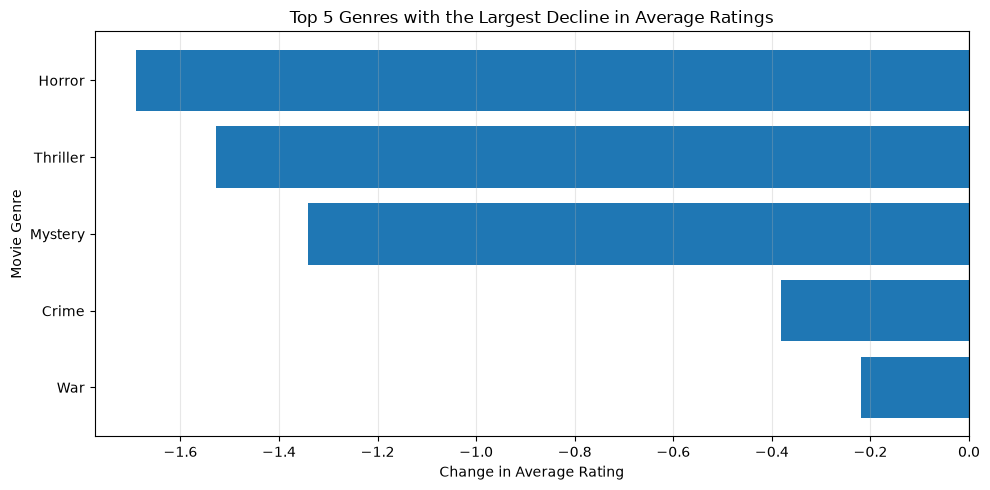

In [6]:
import matplotlib.pyplot as plt

# Reverse order for easier visualization
plot_data = top5_decline.sort_values("rating_change", ascending=False)

plt.figure(figsize=(10, 5))

plt.barh(
    plot_data.index,
    plot_data["rating_change"]
)

plt.xlabel("Change in Average Rating")
plt.ylabel("Movie Genre")
plt.title("Top 5 Genres with the Largest Decline in Average Ratings")

plt.axvline(0, color="black", linewidth=0.8)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



### 2.4 Results and Interpretation

The analysis identified the five genres with the largest decline in average annual ratings between their first and last available years.

| Genre | First Year | Last Year | Rating Change |
|---|---|---|---|
| Horror | 1995 | 2009 | -1.690 |
| Thriller | 1995 | 2009 | -1.528 |
| Mystery | 1995 | 2009 | -1.341 |
| Crime | 1995 | 2009 | -0.381 |
| War | 1996 | 2009 | -0.219 |

**Key Findings:**

Horror experienced the largest observed decrease in average ratings, followed by Thriller and Mystery.

However, the results reveal an important limitation: the first-year averages for Horror, Thriller, and Mystery are each based on only one rating, while Crime is based on two ratings.

Consequently, these averages are highly sensitive to individual user opinions and may not accurately represent the overall rating tendencies of their respective genres.

War provides a more substantial initial sample, with 59,973 ratings in 1996.

**Conclusion:**

Although the initial ranking identifies the largest numerical declines, the reliability of these results is affected by differences in sample size.

The next section investigates the relationship between rating variability and the number of observations, introducing a more statistically reliable comparison.


## 3. Accounting for Rating Variability and Sample Size

### 3.1 Objective

The previous analysis compared average ratings between the first and last available years for each movie genre.

However, the reliability of a sample mean depends on the number of ratings used to calculate it.

In this section, we investigate the relationship between sample size and uncertainty by calculating the standard deviation, standard error of the mean (SEM), and approximate confidence intervals.

We then reassess the observed rating declines while accounting for differences in sample size.


### 3.1.1 Quantifying Uncertainty

For every genre-year pair, we calculate the sample standard deviation (`std_rating`), rating count (`n_ratings`) and standard error of the estimated mean: `SEM = s / sqrt(n)`. Approximate 95% confidence intervals use `mean ± 1.96 × SEM`. For a single rating, the sample standard deviation and SEM are undefined. These intervals are illustrative and assume independent observations; repeated ratings from users and shared movies may violate that assumption.

In [7]:

import numpy as np

# Calculate statistics for each genre and year
genre_stats = (
    genre_df.groupby(["genres", "year"])
    .agg(
        mean_rating=("rating", "mean"),
        std_rating=("rating", "std"),
        n_ratings=("rating", "size")
    )
    .reset_index()
)

# Standard error of the mean
genre_stats["sem"] = (
    genre_stats["std_rating"]
    / np.sqrt(genre_stats["n_ratings"])
)

# Approximate 95% confidence intervals
genre_stats["ci_lower"] = (
    genre_stats["mean_rating"] - 1.96 * genre_stats["sem"]
)

genre_stats["ci_upper"] = (
    genre_stats["mean_rating"] + 1.96 * genre_stats["sem"]
)

# Inspect the statistics
display(genre_stats.head(15).round(4))


,genres,year,mean_rating,std_rating,n_ratings,sem,ci_lower,ci_upper
0,(no genres listed),2004,2.7500,1.0607,2,0.7500,1.2800,4.2200
1,(no genres listed),2007,4.0000,1.3229,3,0.7638,2.5030,5.4970
2,(no genres listed),2008,4.0000,0.7071,2,0.5000,3.0200,4.9800
3,Action,1995,3.0000,NaN,1,NaN,NaN,NaN
4,Action,1996,3.4405,0.9601,331387,0.0017,3.4372,3.4438
5,Action,1997,3.5399,0.9957,129587,0.0028,3.5345,3.5453
6,Action,1998,3.4401,1.1234,55068,0.0048,3.4307,3.4495
7,Action,1999,3.4480,1.1463,194594,0.0026,3.4429,3.4531
8,Action,2000,3.4723,1.1343,330156,0.0020,3.4684,3.4762
9,Action,2001,3.4646,1.1237,201279,0.0025,3.4597,3.4696



### 3.2 Filtering Low-Sample Observations

The initial genre ranking was strongly affected by years containing only one or two ratings.

To improve the reliability of the comparison, a minimum threshold of 100 ratings per genre-year is introduced.

Only genre-year combinations meeting this threshold are retained. The first and last qualifying years are then compared for each genre.

This approach reduces the influence of extremely small samples. However, it is a heuristic filtering method rather than a formal statistical significance test, and it may change the comparison years.


In [8]:

# Minimum sample size per genre-year
min_ratings = 100

# Keep only sufficiently represented genre-year combinations
filtered_stats = genre_stats[
    genre_stats["n_ratings"] >= min_ratings
].copy()

# Sort by genre and year
filtered_stats = filtered_stats.sort_values(["genres", "year"])

# Identify first and last qualifying years
first_filtered = filtered_stats.groupby("genres").first()
last_filtered = filtered_stats.groupby("genres").last()

# Build the adjusted comparison
adjusted_decline = pd.DataFrame({
    "first_year": first_filtered["year"],
    "last_year": last_filtered["year"],
    "first_avg_rating": first_filtered["mean_rating"],
    "last_avg_rating": last_filtered["mean_rating"],
    "first_year_count": first_filtered["n_ratings"],
    "last_year_count": last_filtered["n_ratings"]
})

# Calculate the adjusted rating change
adjusted_decline["rating_change"] = (
    adjusted_decline["last_avg_rating"]
    - adjusted_decline["first_avg_rating"]
)

# Exclude genres with only one qualifying year
adjusted_decline = adjusted_decline[
    adjusted_decline["first_year"]
    < adjusted_decline["last_year"]
]

# Top five largest adjusted declines
top5_adjusted = adjusted_decline.sort_values(
    "rating_change"
).head(5)

display(top5_adjusted.round(3))


,first_year,last_year,first_avg_rating,last_avg_rating,first_year_count,last_year_count,rating_change
genres,,,,,,,
Horror,1996,2009,3.599,3.310,51680,1224,-0.289
War,1996,2009,3.943,3.724,59973,765,-0.219
Documentary,1996,2009,3.867,3.682,4736,195,-0.185
Romance,1996,2009,3.618,3.444,231765,2759,-0.174
Musical,1996,2009,3.631,3.466,55378,680,-0.165


### 3.2.1 Uncertainty of the Adjusted Change

For the first and last qualifying genre-years, the estimated difference is `last_mean - first_mean`. Assuming independent observations, its approximate standard error is `sqrt(SEM_first² + SEM_last²)`, yielding an illustrative 95% interval `change ± 1.96 × SE_change`. We report a descriptive z-ratio but **do not interpret it as a formal significance test**, because ratings are correlated by users and films and the endpoint years were selected from the data.

In [9]:
# Confidence intervals for the changes in the selected qualifying years
first_sem = first_filtered["sem"]
last_sem = last_filtered["sem"]
change_uncertainty = adjusted_decline.copy()
change_uncertainty["sem_change"] = np.sqrt(
    first_sem.loc[change_uncertainty.index] ** 2
    + last_sem.loc[change_uncertainty.index] ** 2
)
change_uncertainty["ci_lower_change"] = change_uncertainty["rating_change"] - 1.96 * change_uncertainty["sem_change"]
change_uncertainty["ci_upper_change"] = change_uncertainty["rating_change"] + 1.96 * change_uncertainty["sem_change"]
change_uncertainty["descriptive_z"] = (
    change_uncertainty["rating_change"] / change_uncertainty["sem_change"].replace(0, np.nan)
)
display(change_uncertainty.loc[top5_adjusted.index,
    ["rating_change", "sem_change", "ci_lower_change", "ci_upper_change", "descriptive_z"]].round(3))

,rating_change,sem_change,ci_lower_change,ci_upper_change,descriptive_z
genres,,,,,
Horror,-0.289,0.031,-0.349,-0.229,-9.414
War,-0.219,0.031,-0.280,-0.159,-7.126
Documentary,-0.185,0.065,-0.312,-0.058,-2.856
Romance,-0.174,0.019,-0.211,-0.138,-9.339
Musical,-0.165,0.038,-0.240,-0.091,-4.354


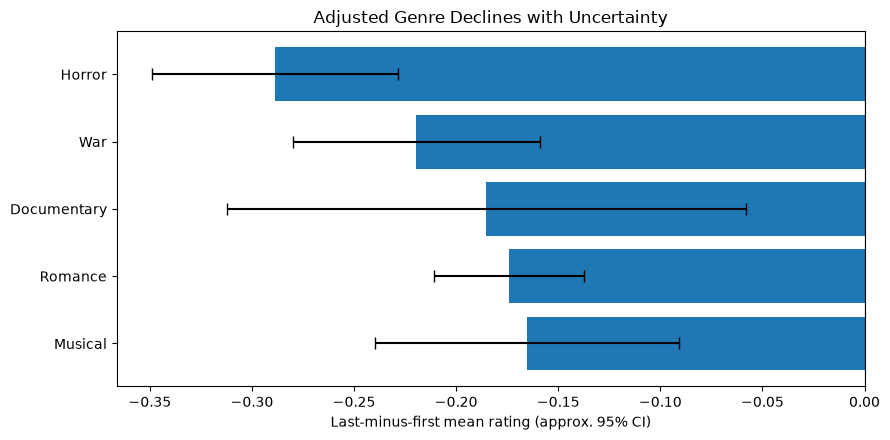

In [10]:
# Plot adjusted change with approximate 95% uncertainty intervals
plot_ci = change_uncertainty.loc[top5_adjusted.index].sort_values("rating_change")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_ci.index, plot_ci["rating_change"], xerr=1.96 * plot_ci["sem_change"], capsize=4)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Last-minus-first mean rating (approx. 95% CI)")
ax.set_title("Adjusted Genre Declines with Uncertainty")
plt.tight_layout()
plt.show()

### 3.2.2 Sensitivity to the Minimum Rating Count

A minimum of 100 ratings is not uniquely justified. Repeating the genre ranking with 50, 100, 500 and 1000 ratings per genre-year reveals whether the top five and comparison years are stable. Any variation should be treated as a limitation of the endpoint approach.

In [11]:
# Recompute rankings across support thresholds
sensitivity_rows = []
for threshold in (50, 100, 500, 1000):
    qualifying = genre_stats.loc[genre_stats["n_ratings"] >= threshold].sort_values(["genres", "year"])
    for genre, group in qualifying.groupby("genres"):
        if group["year"].nunique() < 2:
            continue
        a, b = group.iloc[0], group.iloc[-1]
        sensitivity_rows.append({"threshold": threshold, "genre": genre,
                                 "first_year": int(a["year"]), "last_year": int(b["year"]),
                                 "change": b["mean_rating"] - a["mean_rating"]})
sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_top5 = (sensitivity_df.sort_values(["threshold", "change"])
                    .groupby("threshold", group_keys=False).head(5))
display(sensitivity_top5.round(3).reset_index(drop=True))

,threshold,genre,first_year,last_year,change
0,50,Horror,1996,2009,-0.289
1,50,War,1996,2009,-0.219
2,50,Documentary,1996,2009,-0.185
3,50,Romance,1996,2009,-0.174
4,50,Musical,1996,2009,-0.165
5,100,Horror,1996,2009,-0.289
6,100,War,1996,2009,-0.219
7,100,Documentary,1996,2009,-0.185
8,100,Romance,1996,2009,-0.174
9,100,Musical,1996,2009,-0.165


**Partial-year caveat:** Confirm the observed last timestamp in the dataset before interpreting 2009 as a full year. If 2009 covers only a short initial interval, annual comparisons using 2009 can be unstable; differences may reflect a partial observation window rather than a genre trend.

In [12]:
# Inspect actual temporal coverage of the ratings data
rating_dates = pd.to_datetime(df["timestamp"], unit="s", utc=True)
print("Earliest rating:", rating_dates.min())
print("Latest rating:", rating_dates.max())
print("Number of 2009 ratings:", int((df["year"] == 2009).sum()))

Earliest rating: 1995-01-09 11:46:49+00:00
Latest rating: 2009-01-05 05:02:16+00:00
Number of 2009 ratings: 14608



### 3.3 Comparison of Original and Adjusted Results

To evaluate the impact of sample-size filtering, we compare the original rating changes with the adjusted changes.

The comparison highlights how low-sample observations can distort the estimated decline in average ratings.


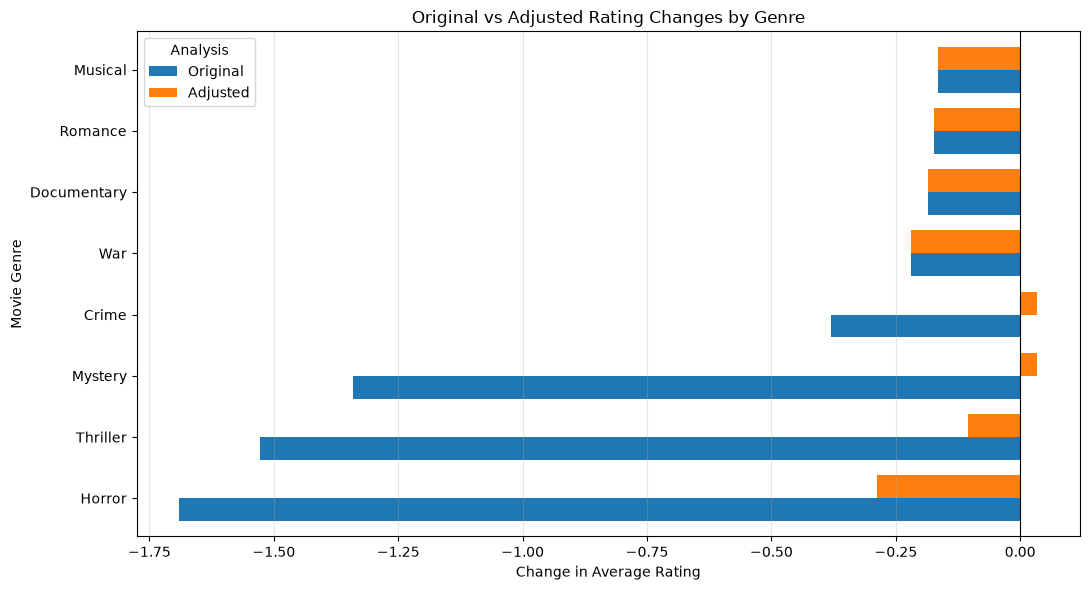

In [13]:

# Compare original and adjusted rating changes
comparison = pd.DataFrame({
    "Original": genre_decline["rating_change"],
    "Adjusted": adjusted_decline["rating_change"]
})

# Select genres appearing in either top-five ranking
selected_genres = list(
    dict.fromkeys(
        list(top5_decline.index) +
        list(top5_adjusted.index)
    )
)

comparison_plot = comparison.loc[selected_genres]

# Create comparison chart
ax = comparison_plot.plot(
    kind="barh",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("Original vs Adjusted Rating Changes by Genre")
ax.set_xlabel("Change in Average Rating")
ax.set_ylabel("Movie Genre")
ax.axvline(0, color="black", linewidth=0.8)
ax.grid(axis="x", alpha=0.3)

plt.legend(title="Analysis")
plt.tight_layout()
plt.show()



### 3.4 Results and Interpretation

The adjusted analysis produced substantially different results compared to the original genre ranking.

**Top 5 Genres After Sample-Size Filtering:**

| Genre | First Year | Last Year | Adjusted Change |
|---|---|---|---|
| Horror | 1996 | 2009 | -0.289 |
| War | 1996 | 2009 | -0.219 |
| Documentary | 1996 | 2009 | -0.185 |
| Romance | 1996 | 2009 | -0.174 |
| Musical | 1996 | 2009 | -0.165 |

**Key Findings:**

- Horror remains the genre with the largest observed decrease, but its estimated decline is reduced from -1.690 to -0.289.
- Thriller, Mystery, and Crime are no longer among the five genres with the largest declines.
- War remains in the top five, while Documentary, Romance, and Musical enter the adjusted ranking.
- The initial large decreases were strongly influenced by genre-year combinations containing very few ratings.

**Statistical Interpretation:**

The standard error of the mean decreases as the number of observations increases, assuming comparable rating variability.

By requiring at least 100 ratings per genre-year, the adjusted analysis avoids comparisons involving extremely small samples.

However, this threshold is heuristic, and the analysis remains descriptive rather than a formal hypothesis test. The results may also depend on the selected threshold.

**Conclusion:**

Accounting for sample size substantially changes the interpretation of rating trends.

The adjusted results provide a more reliable descriptive comparison, demonstrating the importance of considering sample size and statistical uncertainty when analyzing user ratings.



## 4. Collaborative Filtering with Gradient Descent

### 4.1 Temporal Train-Test Split

The dataset is divided chronologically to evaluate the recommendation system.

- Training set: Ratings submitted before 2008.
- Test set: Ratings submitted during 2008 and 2009.

This temporal split simulates predicting future ratings from historical interactions.

A matrix factorization model will be trained using stochastic gradient descent and evaluated using Root Mean Squared Error (RMSE).

The test dataset will remain excluded from model training to prevent data leakage.

In [14]:

# Create temporal training and test datasets
train_df = df.loc[
    df["year"] < 2008,
    ["userId", "movieId", "rating"]
].copy()

test_df = df.loc[
    df["year"].isin([2008, 2009]),
    ["userId", "movieId", "rating"]
].copy()

# Display dataset sizes
print("Training ratings:", len(train_df))
print("Test ratings:", len(test_df))

print(
    "Training percentage:",
    round(len(train_df) / len(df) * 100, 2), "%"
)

print(
    "Test percentage:",
    round(len(test_df) / len(df) * 100, 2), "%"
)

# Check for temporal overlap
print(
    "All records accounted for:",
    len(train_df) + len(test_df) == len(df)
)

# Check users and movies available in training
train_users = set(train_df["userId"])
train_movies = set(train_df["movieId"])

unknown_users = ~test_df["userId"].isin(train_users)
unknown_movies = ~test_df["movieId"].isin(train_movies)

print("Test ratings with unseen users:", unknown_users.sum())
print("Test ratings with unseen movies:", unknown_movies.sum())


Training ratings: 9211829
Test ratings: 788225
Training percentage: 92.12 %
Test percentage: 7.88 %
All records accounted for: True
Test ratings with unseen users: 620485
Test ratings with unseen movies: 49087



### 4.2 Preparing Data for Matrix Factorization

Matrix factorization represents users and movies using low-dimensional latent feature vectors.

To train the model efficiently, user IDs and movie IDs are converted into consecutive integer indices.

This allows the model to store user and movie embeddings in compact NumPy arrays without creating a large dense user-movie rating matrix.

The mappings are constructed exclusively from the training dataset to avoid data leakage.

In [15]:

import numpy as np

# Extract unique users and movies from training data
unique_users = np.sort(train_df["userId"].unique())
unique_movies = np.sort(train_df["movieId"].unique())

# Create ID-to-index mappings
user_to_idx = {
    user_id: idx
    for idx, user_id in enumerate(unique_users)
}

movie_to_idx = {
    movie_id: idx
    for idx, movie_id in enumerate(unique_movies)
}

# Convert training IDs to indices
train_user_idx = train_df["userId"].map(
    user_to_idx
).to_numpy(dtype=np.int32)

train_movie_idx = train_df["movieId"].map(
    movie_to_idx
).to_numpy(dtype=np.int32)

# Store ratings as float32
train_ratings = train_df["rating"].to_numpy(
    dtype=np.float32
)

# Model dimensions
n_users = len(unique_users)
n_movies = len(unique_movies)

print("Number of training users:", n_users)
print("Number of training movies:", n_movies)
print("Number of training ratings:", len(train_ratings))

print("User index range:", train_user_idx.min(), "-", train_user_idx.max())
print("Movie index range:", train_movie_idx.min(), "-", train_movie_idx.max())

print("Average training rating:", round(float(train_ratings.mean()), 4))


Number of training users: 65514
Number of training movies: 9702
Number of training ratings: 9211829
User index range: 0 - 65513
Movie index range: 0 - 9701
Average training rating: 3.51



### 4.3 Matrix Factorization with Stochastic Gradient Descent

A matrix factorization model is implemented to predict user ratings based on latent user and movie features.

The predicted rating is defined as:

\[
\hat{r}_{ui} = \mu + b_u + b_i + p_u^T q_i
\]

Where:
- \(\mu\): Global mean rating.
- \(b_u\): User-specific bias.
- \(b_i\): Movie-specific bias.
- \(p_u\): User latent factor vector.
- \(q_i\): Movie latent factor vector.

The model is optimized using Stochastic Gradient Descent (SGD) with L2 regularization to reduce overfitting.

Numba is used to accelerate training on the MovieLens 10M dataset.


#### 4.3.1 Checking the Numerical Environment

Numba accelerates the SGD loop through just-in-time compilation. Required packages should be installed from `requirements.txt` before running the notebook; package installation is not performed during notebook execution.

In [16]:

try:
    import numba
    print("Numba version:", numba.__version__)
except ImportError:
    print("Numba is not installed.")


Numba version: 0.68.0


#### 4.3.2 Defining the SGD Update Rule

The function updates user/movie biases and latent vectors for every observed training rating using SGD with L2 regularization. It returns **online training RMSE**, evaluated while parameters are changing, rather than a final epoch-level or test-set RMSE.

In [17]:

from numba import njit

@njit
def train_sgd(
    user_indices,
    movie_indices,
    ratings,
    user_factors,
    movie_factors,
    user_bias,
    movie_bias,
    global_mean,
    learning_rate,
    regularization
):
    squared_error = 0.0

    for idx in range(len(ratings)):
        u = user_indices[idx]
        i = movie_indices[idx]
        actual = ratings[idx]

        prediction = global_mean + user_bias[u] + movie_bias[i]

        for k in range(user_factors.shape[1]):
            prediction += user_factors[u, k] * movie_factors[i, k]

        error = actual - prediction
        squared_error += error * error

        # Update biases
        user_bias[u] += learning_rate * (
            error - regularization * user_bias[u]
        )

        movie_bias[i] += learning_rate * (
            error - regularization * movie_bias[i]
        )

        # Update latent factors
        for k in range(user_factors.shape[1]):
            pu = user_factors[u, k]
            qi = movie_factors[i, k]

            user_factors[u, k] += learning_rate * (
                error * qi - regularization * pu
            )

            movie_factors[i, k] += learning_rate * (
                error * pu - regularization * qi
            )

    return np.sqrt(squared_error / len(ratings))



### 4.4 Model Initialization

The matrix factorization model is initialized with 20 latent factors per user and movie.

User and movie embeddings are initialized with small random values, while user and movie biases start at zero.

The initial hyperparameters are:

- Latent factors: 20
- Learning rate: 0.005
- L2 regularization: 0.02
- Training epochs: 5
- Random seed: 42

These values provide an initial configuration and can be adjusted based on model performance.

In [18]:

# Model hyperparameters
n_factors = 20
learning_rate = 0.005
regularization = 0.02
n_epochs = 5

# Reproducibility
rng = np.random.default_rng(42)

# Initialize latent factors
user_factors = rng.normal(
    0, 0.1, size=(n_users, n_factors)
).astype(np.float32)

movie_factors = rng.normal(
    0, 0.1, size=(n_movies, n_factors)
).astype(np.float32)

# Initialize biases
user_bias = np.zeros(n_users, dtype=np.float32)
movie_bias = np.zeros(n_movies, dtype=np.float32)

# Global mean rating
global_mean = float(train_ratings.mean())

print("User factors shape:", user_factors.shape)
print("Movie factors shape:", movie_factors.shape)
print("Global mean:", round(global_mean, 4))


User factors shape: (65514, 20)
Movie factors shape: (9702, 20)
Global mean: 3.51



### 4.5 Model Training

The model is trained using Stochastic Gradient Descent over five epochs.

Training interactions are randomly shuffled at the beginning of each epoch to reduce ordering bias.

The training process updates user biases, movie biases, and latent factor vectors to minimize prediction errors with L2 regularization.

The optimization error is recorded after each epoch to monitor learning progress.


In [19]:

import time

training_errors = []

for epoch in range(n_epochs):
    start_time = time.time()

    # Shuffle training observations each epoch
    indices = rng.permutation(len(train_ratings))

    epoch_rmse = train_sgd(
        train_user_idx[indices],
        train_movie_idx[indices],
        train_ratings[indices],
        user_factors,
        movie_factors,
        user_bias,
        movie_bias,
        global_mean,
        learning_rate,
        regularization
    )

    training_errors.append(epoch_rmse)

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch + 1}/{n_epochs} | "
        f"Online RMSE: {epoch_rmse:.4f} | "
        f"Time: {elapsed:.1f}s"
    )


Epoch 1/5 | Online RMSE: 0.9114 | Time: 0.7s
Epoch 2/5 | Online RMSE: 0.8771 | Time: 0.3s
Epoch 3/5 | Online RMSE: 0.8691 | Time: 0.3s
Epoch 4/5 | Online RMSE: 0.8620 | Time: 0.3s
Epoch 5/5 | Online RMSE: 0.8515 | Time: 0.3s


#### 4.5.1 Interpreting Training Progress

The line chart below shows online RMSE after each pass through the training interactions. A downward trend indicates improvement during optimization, but is **not** evidence of improved generalization by itself.

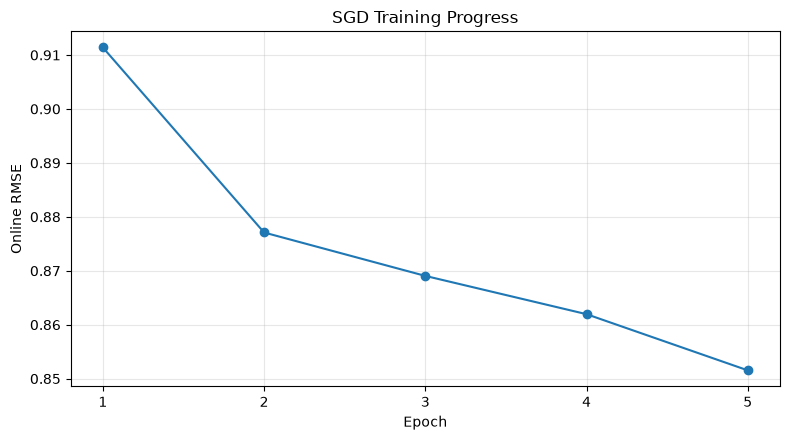

In [20]:
# Training progress visualization (online RMSE, not test RMSE)
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(training_errors) + 1), training_errors, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Online RMSE")
plt.title("SGD Training Progress")
plt.xticks(range(1, len(training_errors) + 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 4.6 Model Evaluation on the Test Dataset

The trained matrix factorization model is evaluated on ratings submitted during 2008 and 2009.

Predictions are generated using the learned global mean, user and movie biases, and latent factor vectors.

Since some users and movies appear only in the test dataset, fallback strategies are introduced to handle cold-start cases.

The prediction error is measured using Root Mean Squared Error (RMSE):

\[
RMSE = \sqrt{\frac{1}{N}\sum_{j=1}^{N}(r_j-\hat{r}_j)^2}
\]

Predictions are clipped to the valid MovieLens rating range of 0.5 to 5.0.

The evaluation includes all test ratings, including those associated with previously unseen users or movies.


#### 4.6.1 Generating Predictions

User and movie IDs from the held-out set are mapped using training-only dictionaries. Observed users and movies receive their learned biases and latent-factor interaction; unknown IDs use the available biases or the global training mean. Scores are clipped to the valid rating range [0.5, 5.0].

In [21]:

# Map test users and movies to training indices
test_user_idx = test_df["userId"].map(user_to_idx)
test_movie_idx = test_df["movieId"].map(movie_to_idx)

# Identify known users and movies
known_users = test_user_idx.notna().to_numpy()
known_movies = test_movie_idx.notna().to_numpy()

# Initialize predictions using the training global mean
predictions = np.full(
    len(test_df),
    global_mean,
    dtype=np.float32
)

# Add user biases for known users
predictions[known_users] += user_bias[
    test_user_idx[known_users].to_numpy(dtype=np.int32)
]

# Add movie biases for known movies
predictions[known_movies] += movie_bias[
    test_movie_idx[known_movies].to_numpy(dtype=np.int32)
]

# Add latent factor interactions when both are known
known_both = known_users & known_movies

u_idx = test_user_idx[known_both].to_numpy(dtype=np.int32)
m_idx = test_movie_idx[known_both].to_numpy(dtype=np.int32)

predictions[known_both] += np.sum(
    user_factors[u_idx] * movie_factors[m_idx],
    axis=1
)

# Restrict predictions to valid rating range
predictions = np.clip(predictions, 0.5, 5.0)

print("Total predictions:", len(predictions))
print("Known user and movie:", known_both.sum())
print("Predictions range:", predictions.min(), "-", predictions.max())


Total predictions: 788225
Known user and movie: 140728
Predictions range: 0.5 - 5.0


#### 4.6.2 MSE, RMSE and Global-Mean Baseline

The exercise specifically requests **mean squared error (MSE)**. We calculate both `MSE = mean((actual - predicted)^2)` and `RMSE = sqrt(MSE)` on the entire 2008–2009 held-out set. All predictions are clipped to the allowed rating scale and fallbacks are used for unseen entities. RMSE is easier to interpret in star-rating units, while MSE directly satisfies the assignment.

In [22]:
# Compute the required MSE and the complementary RMSE
actual_ratings = test_df["rating"].to_numpy(dtype=np.float32)
residuals = actual_ratings.astype(np.float64) - predictions.astype(np.float64)
test_mse = np.mean(residuals ** 2)
test_rmse = np.sqrt(test_mse)

baseline_predictions = np.full(len(test_df), global_mean, dtype=np.float32)
baseline_mse = np.mean((actual_ratings.astype(np.float64) - baseline_predictions.astype(np.float64)) ** 2)
baseline_rmse = np.sqrt(baseline_mse)
print(f"Full pipeline Test MSE: {test_mse:.4f}")
print(f"Full pipeline Test RMSE: {test_rmse:.4f}")
print(f"Global mean baseline MSE: {baseline_mse:.4f}")
print(f"Global mean baseline RMSE: {baseline_rmse:.4f}")
print(f"RMSE reduction vs global mean: {(baseline_rmse-test_rmse)/baseline_rmse*100:.2f}%")

Full pipeline Test MSE: 0.8209
Full pipeline Test RMSE: 0.9060
Global mean baseline MSE: 0.9980
Global mean baseline RMSE: 0.9990
RMSE reduction vs global mean: 9.30%


#### 4.6.2.1 Factor Ablation: Bias-Only Comparisons

Besides the global mean, compare (i) global mean + **learned movie bias** and (ii) global mean + **learned user and movie biases**, applying the same known-ID fallbacks. These are **ablations of the trained MF parameters**, not separately trained optimal bias-only models. For observations with both user and movie known, their difference from full MF isolates the incremental value of the latent-factor interaction under these learned parameters.

In [23]:
# Baseline predictions and metric table using train-learned parameters only
movie_bias_predictions = np.full(len(test_df), global_mean, dtype=np.float32)
movie_bias_predictions[known_movies] += movie_bias[test_movie_idx[known_movies].to_numpy(dtype=np.int32)]
movie_bias_predictions = np.clip(movie_bias_predictions, 0.5, 5.0)

bias_predictions = movie_bias_predictions.copy()
bias_predictions[known_users] += user_bias[test_user_idx[known_users].to_numpy(dtype=np.int32)]
bias_predictions = np.clip(bias_predictions, 0.5, 5.0)

def mse_rmse(true, pred):
    diff = true.astype(np.float64) - pred.astype(np.float64)
    mse = np.mean(diff ** 2)
    return mse, np.sqrt(mse)

metrics = []
for name, pred in [("Global mean", baseline_predictions),
                   ("Movie bias (MF ablation)", movie_bias_predictions),
                   ("User + movie biases (MF ablation)", bias_predictions),
                   ("Full MF + cold-start fallbacks", predictions)]:
    mse, rmse = mse_rmse(actual_ratings, pred)
    known_mse, known_rmse = mse_rmse(actual_ratings[known_both], pred[known_both])
    metrics.append({"model": name, "test_mse": mse, "test_rmse": rmse,
                    "known_both_rmse": known_rmse})
metrics_df = pd.DataFrame(metrics)
print("MSE (required by assignment):", f"{test_mse:.4f}")
display(metrics_df.round(4))

MSE (required by assignment): 0.8209


,model,test_mse,test_rmse,known_both_rmse
0,Global mean,0.9980,0.9990,0.9668
1,Movie bias (MF ablation),0.8440,0.9187,0.8817
2,User + movie biases (MF ablation),0.8234,0.9074,0.8199
3,Full MF + cold-start fallbacks,0.8209,0.9060,0.8114


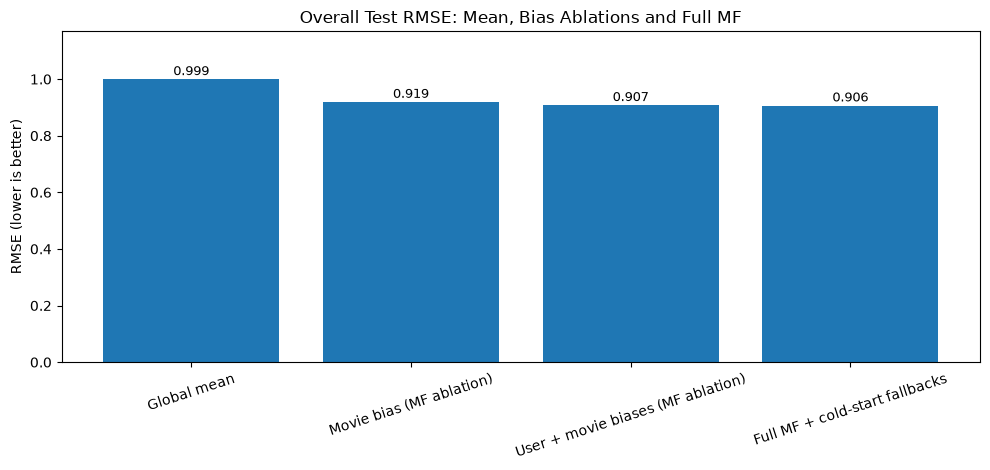

In [24]:
# All methods compared on the same test records
fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.bar(metrics_df["model"], metrics_df["test_rmse"])
for bar, value in zip(bars, metrics_df["test_rmse"]):
    ax.text(bar.get_x() + bar.get_width()/2, value + .015, f"{value:.3f}", ha="center", fontsize=9)
ax.set_ylabel("RMSE (lower is better)")
ax.set_ylim(0, max(metrics_df["test_rmse"]) * 1.17)
ax.tick_params(axis="x", labelrotation=18)
ax.set_title("Overall Test RMSE: Mean, Bias Ablations and Full MF")
plt.tight_layout()
plt.show()

#### 4.6.3 Comparison Across Predictors

The chart includes the constant baseline, the two bias ablations and the full matrix-factorization pipeline. Since most held-out ratings involve unseen users, we report performance on the **known-user-and-movie subset** separately in the following table; this is where the learned latent factors can contribute directly.

The next cells compute the bias-only ablations and plot their errors. They use exactly the same held-out target values and pre-2008 learned parameters.


### 4.7 Evaluation by User and Movie Availability

To better understand the model's performance, test ratings are divided into four categories based on whether their users and movies appeared in the training data.

We evaluate prediction accuracy separately for each category and verify that every test rating belongs to exactly one group.

This analysis helps identify the limitations of matrix factorization when dealing with cold-start users and movies.

In [25]:

# Rebuild masks as NumPy arrays to avoid index alignment issues
known_users = test_user_idx.notna().to_numpy()
known_movies = test_movie_idx.notna().to_numpy()

known_both = known_users & known_movies
unknown_user_only = (~known_users) & known_movies
unknown_movie_only = known_users & (~known_movies)
unknown_both = (~known_users) & (~known_movies)

categories = {
    "Known user and movie": known_both,
    "Unknown user, known movie": unknown_user_only,
    "Known user, unknown movie": unknown_movie_only,
    "Unknown user and movie": unknown_both
}

# Validate category counts
total_count = sum(mask.sum() for mask in categories.values())

print("Test dataset size:", len(test_df))
print("Total categorized ratings:", total_count)
print("All ratings accounted for:", total_count == len(test_df))

# RMSE by category
results = []

for category, mask in categories.items():
    count = int(mask.sum())

    if count > 0:
        rmse = np.sqrt(
            np.mean(
                (
                    actual_ratings[mask].astype(np.float64)
                    - predictions[mask].astype(np.float64)
                ) ** 2
            )
        )
    else:
        rmse = np.nan

    results.append({
        "Category": category,
        "Ratings": count,
        "Percentage": count / len(test_df) * 100,
        "RMSE": rmse
    })

category_results = pd.DataFrame(results)

display(category_results.round(4))


Test dataset size: 788225
Total categorized ratings: 788225
All ratings accounted for: True


,Category,Ratings,Percentage,RMSE
0,Known user and movie,140728,17.8538,0.8114
1,"Unknown user, known movie",598410,75.9187,0.9210
2,"Known user, unknown movie",27012,3.4269,0.8869
3,Unknown user and movie,22075,2.8006,1.0751


#### 4.7.1 Evaluation Consistency Check

The weighted average of category-level **squared** RMSE values should equal the overall mean squared error. Taking its square root provides a useful internal consistency check of the partition and metrics.

In [26]:

# Verify consistency of evaluation metrics
weighted_rmse = np.sqrt(
    np.average(
        category_results["RMSE"] ** 2,
        weights=category_results["Ratings"]
    )
)

print(f"Overall Test RMSE: {test_rmse:.4f}")
print(f"RMSE from categories: {weighted_rmse:.4f}")

assert np.isclose(test_rmse, weighted_rmse, atol=1e-5)
print("Evaluation consistency check: PASSED")


Overall Test RMSE: 0.9060
RMSE from categories: 0.9060
Evaluation consistency check: PASSED


#### 4.7.2 Cold-Start Category Performance

The plot compares prediction errors across the four mutually exclusive availability categories. Interpretation should consider both RMSE and the number of ratings per category.

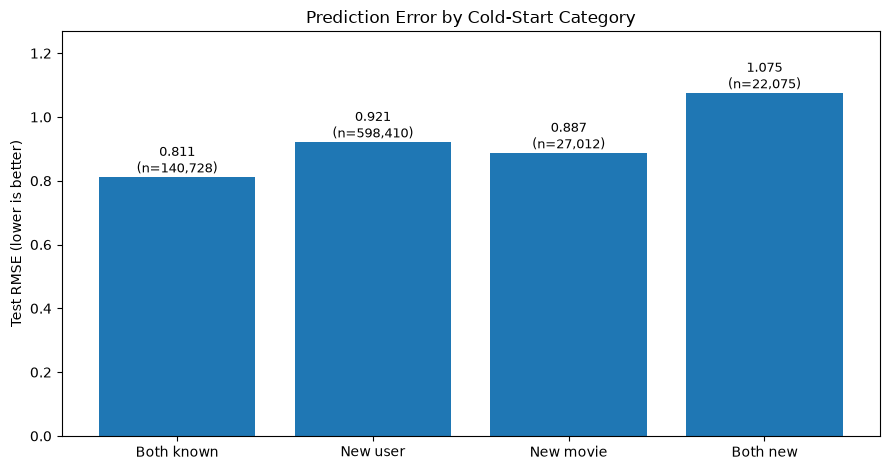

In [27]:
# Visualize RMSE for each cold-start category
fig, ax = plt.subplots(figsize=(9, 4.8))
labels = ["Both known", "New user", "New movie", "Both new"]
values = category_results["RMSE"].to_numpy()
counts = category_results["Ratings"].to_numpy()
bars = ax.bar(labels, values)
ax.set_ylabel("Test RMSE (lower is better)")
ax.set_title("Prediction Error by Cold-Start Category")
ax.set_ylim(0, max(values) * 1.18)
for bar, val, count in zip(bars, values, counts):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.015,
            f"{val:.3f}\n(n={count:,})", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

### 4.8 Interpretation of Held-Out Evaluation

The full model's **MSE** and **RMSE** are printed in Section 4.6.2. It is essential to distinguish the **entire prediction pipeline** (which uses fallbacks for cold-start cases) from the MF latent-factor contribution. Roughly three quarters of held-out ratings involve unseen users and known movies, so movie bias has substantial influence on the overall result. The bias-only ablations and **known-user-and-movie RMSE** show how much additional benefit the latent factors provide under the learned parameters.

The temporal split avoids using 2008–2009 ratings during model training. The random initialization is reproducible in a fixed environment, but the hyperparameters were not tuned on a separate validation period. The optimizer is **stochastic gradient descent**, an efficient gradient-descent variant updating the parameters on individual observed ratings rather than evaluating the complete gradient over millions of records.


## 5. Top 10 Movie Recommendations for a New User

### 5.1 Addressing the Cold-Start Problem

A new user has no previous ratings or interaction history. Therefore, a collaborative filtering model cannot estimate personalized user latent factors.

To address this cold-start problem, we use a popularity-adjusted ranking based on movie ratings from the training dataset.

Instead of ranking movies solely by their average rating, we apply a Bayesian weighted rating formula that accounts for both rating quality and the number of ratings.

This prevents movies with very few exceptionally high ratings from dominating the recommendations.


### 5.2 Computing Bayesian Weighted Ratings

Candidate movies are summarized using ratings from the training period only. The weighted score shrinks each movie’s empirical mean toward the global training mean, with the strength of shrinkage controlled by `m`, chosen here as the 75th percentile of rating counts. This is a heuristic choice.

In [28]:

# Calculate movie rating statistics using training data only
movie_stats = (
    train_df.groupby("movieId")
    .agg(
        mean_rating=("rating", "mean"),
        num_ratings=("rating", "size")
    )
    .reset_index()
)

# Global mean rating
C = float(train_df["rating"].mean())

# Bayesian smoothing parameter (75th percentile of rating counts)
m = float(movie_stats["num_ratings"].quantile(0.75))

# Calculate Bayesian weighted rating
movie_stats["weighted_rating"] = (
    (movie_stats["num_ratings"] /
     (movie_stats["num_ratings"] + m))
    * movie_stats["mean_rating"]
    +
    (m / (movie_stats["num_ratings"] + m)) * C
)

# Add movie titles and genres
movie_stats = movie_stats.merge(
    movies[["movieId", "title", "genres"]],
    on="movieId",
    how="left",
    validate="one_to_one"
)

print("Global average rating:", round(C, 4))
print("Bayesian smoothing parameter:", round(m, 2))
print("Movies ranked:", len(movie_stats))


Global average rating: 3.51
Bayesian smoothing parameter: 690.0
Movies ranked: 9702


### 5.3 Selecting Ten Cold-Start Recommendations

Movies are ordered by the Bayesian weighted rating (with rating count used to break ties). This offers reliable community favorites to a new user, but does **not** yet adapt to their individual tastes.

In [29]:

# Rank movies using Bayesian weighted ratings
top10_new_user = (
    movie_stats
    .sort_values(
        ["weighted_rating", "num_ratings"],
        ascending=[False, False]
    )
    .head(10)
    .copy()
)

# Display recommendation results
display(
    top10_new_user[
        ["title", "genres", "mean_rating",
         "num_ratings", "weighted_rating"]
    ].round(3)
)


,title,genres,mean_rating,num_ratings,weighted_rating
315,"Shawshank Redemption, The (1994)",Drama,4.461,28589,4.439
843,"Godfather, The (1972)",Crime|Drama,4.426,17926,4.392
523,Schindler's List (1993),Drama|War,4.378,24027,4.354
49,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,4.371,22205,4.345
895,Casablanca (1942),Drama|Romance,4.336,11637,4.289
887,Rear Window (1954),Mystery|Thriller,4.333,8245,4.270
1195,"Godfather: Part II, The (1974)",Crime|Drama,4.312,12087,4.268
1169,One Flew Over the Cuckoo's Nest (1975),Comedy|Drama,4.306,13094,4.266
737,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.311,10790,4.262
1173,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure,4.274,19906,4.248



### 5.4 Results and Interpretation

A popularity-adjusted recommendation strategy was developed to address the new-user cold-start problem.

The Bayesian weighted rating method was applied to 9,702 movies using training data only. The global average rating was approximately 3.51, and the smoothing parameter was set to 690 ratings.

**Top 10 Recommendations:**

| Rank | Movie | Weighted Rating |
|---|---|---|
| 1 | The Shawshank Redemption (1994) | 4.439 |
| 2 | The Godfather (1972) | 4.392 |
| 3 | Schindler's List (1993) | 4.354 |
| 4 | The Usual Suspects (1995) | 4.345 |
| 5 | Casablanca (1942) | 4.289 |
| 6 | Rear Window (1954) | 4.270 |
| 7 | The Godfather: Part II (1974) | 4.268 |
| 8 | One Flew Over the Cuckoo's Nest (1975) | 4.266 |
| 9 | Dr. Strangelove (1964) | 4.262 |
| 10 | Raiders of the Lost Ark (1981) | 4.248 |

**Interpretation:**

The recommended movies have strong average ratings supported by substantial numbers of user evaluations.

Bayesian smoothing reduces the influence of movies with very few ratings and produces a more reliable ranking than using raw average ratings alone.

However, the recommendations are not personalized because no information about the new user's preferences is available.

**Conclusion:**

Popularity-adjusted rankings provide a practical solution to the new-user cold-start problem.

Once a user provides initial preferences, the recommendation system can transition toward personalized recommendations using the trained collaborative filtering model.


## 6. Personalized Recommendations Based on Movie Preferences

### 6.1 Identifying and Verifying the Favorite Movies

The new user likes **Iron Man (2008)**, **300 (2007)** and **Transformers (2007)**. We identify their exact MovieLens IDs and check whether each movie received ratings in the pre-2008 training set. This check prevents us from assuming that the trained matrix-factorization model contains an embedding for each favorite. Movie metadata can be used to interpret the user's stated preferences, but held-out 2008–2009 ratings remain excluded from model development.

In [30]:
# Verify exact favorite IDs and historical training availability
favorite_movie_ids = [59315, 51662, 53996]
expected_titles = {59315: "Iron Man (2008)", 51662: "300 (2007)", 53996: "Transformers (2007)"}
favorite_movies = movies.loc[movies["movieId"].isin(favorite_movie_ids),
                            ["movieId", "title", "genres"]].copy()
assert len(favorite_movies) == 3
for movie_id, title in expected_titles.items():
    assert favorite_movies.loc[favorite_movies["movieId"] == movie_id, "title"].iloc[0] == title

training_counts = train_df.groupby("movieId").size()
favorite_movies["training_ratings"] = favorite_movies["movieId"].map(training_counts).fillna(0).astype(int)
favorite_movies["has_trained_embedding"] = favorite_movies["movieId"].isin(movie_to_idx)
display(favorite_movies.sort_values("movieId"))

,movieId,title,genres,training_ratings,has_trained_embedding
9820,51662,300 (2007),Action|Fantasy|War,1341,True
9939,53996,Transformers (2007),Action|Adventure|Sci-Fi|Thriller,659,True
10262,59315,Iron Man (2008),Action|Adventure|Sci-Fi,0,False


### 6.2 Genre-Based Cold-Start Profile

A new user's latent factor vector is not learned during standard matrix-factorization training. **Fold-in** is possible when the user supplies numeric ratings for movies that have trained embeddings; it is not applied here because the input is only three *liked* movies and some may be unseen in training. We therefore use **content-based cosine similarity**, which handles all three favorites without using test ratings.

We convert movie genres to binary vectors, average the three favorite vectors into a user profile, and compare each candidate using cosine similarity. Unlike summing genre weights, cosine similarity adjusts for the length of each movie's genre vector. This does not eliminate genre-tag limitations, but reduces the automatic advantage given to movies with many tags.

In [31]:
# Construct a profile from binary genre vectors (all metadata, no test ratings)
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics.pairwise import cosine_similarity

# Build a consistent vector space for every movie
movie_genre_lists = movies["genres"].str.split("|")
mlb = MultiLabelBinarizer()
all_genre_vectors = mlb.fit_transform(movie_genre_lists).astype(np.float32)
genre_vector_df = pd.DataFrame(all_genre_vectors, index=movies["movieId"], columns=mlb.classes_)

favorite_vectors = genre_vector_df.loc[favorite_movie_ids].to_numpy(dtype=np.float32)
user_genre_profile = favorite_vectors.mean(axis=0)
preference_df = pd.DataFrame({"Genre": mlb.classes_, "Preference Weight": user_genre_profile})
preference_df = preference_df.query("`Preference Weight` > 0").sort_values("Preference Weight", ascending=False)
print("Favorite movies and training availability:")
display(favorite_movies)
print("Genre prevalence across the three favorites (1 = present in all 3):")
display(preference_df.round(3))

Favorite movies and training availability:


,movieId,title,genres,training_ratings,has_trained_embedding
9820,51662,300 (2007),Action|Fantasy|War,1341,True
9939,53996,Transformers (2007),Action|Adventure|Sci-Fi|Thriller,659,True
10262,59315,Iron Man (2008),Action|Adventure|Sci-Fi,0,False


Genre prevalence across the three favorites (1 = present in all 3):


,Genre,Preference Weight
1,Action,1.000
2,Adventure,0.667
16,Sci-Fi,0.667
9,Fantasy,0.333
17,Thriller,0.333
18,War,0.333


### 6.3 Cosine Similarity and Quality-Aware Ranking

We rank **training-known candidate movies** using three components: cosine similarity with the favorite-movie genre profile (**65%**), quality measured by the training-only Bayesian weighted rating (**25%**), and a small release-year proximity preference (**10%**, increasing from 1995 to 2007). Release year is extracted from each movie's title, not from rating timestamps.

The year preference reflects the user's selection of three 2007–2008 blockbusters, but it is **only a heuristic** and cannot infer a genuine preference for recent releases from three examples. Candidates are restricted to release years 1995–2007, at least 100 pre-2008 ratings, and a weighted rating of at least 3.5. These are transparent, unoptimized design choices, not tuned hyperparameters. We do not use any test-set ratings or pretend that 2008 films have been trained in the historical model.

The recommendation score is a ranking heuristic, not a predicted star rating. In a deployed system, one could retrain on ratings available at recommendation time or fold in the new user after collecting explicit numeric ratings.

In [32]:
# Historical candidates, with labels and training-based Bayesian ratings
recommendation_candidates = movie_stats.loc[
    ~movie_stats["movieId"].isin(favorite_movie_ids)
].copy()

candidate_vectors = genre_vector_df.loc[recommendation_candidates["movieId"]].to_numpy(dtype=np.float32)
recommendation_candidates["genre_similarity"] = cosine_similarity(
    candidate_vectors, user_genre_profile.reshape(1, -1)
).ravel()

# Release dates are title metadata; not evaluation timestamps
recommendation_candidates["release_year"] = pd.to_numeric(
    recommendation_candidates["title"].str.extract(r"\((\d{4})\)$")[0], errors="coerce"
).to_numpy()
recommendation_candidates["quality_norm"] = (
    (recommendation_candidates["weighted_rating"] - 0.5) / 4.5
).clip(0, 1)
recommendation_candidates["recency_norm"] = (
    (recommendation_candidates["release_year"] - 1995) / (2007 - 1995)
).clip(0, 1).fillna(0)
recommendation_candidates["personalized_score"] = (
    0.65 * recommendation_candidates["genre_similarity"]
    + 0.25 * recommendation_candidates["quality_norm"]
    + 0.10 * recommendation_candidates["recency_norm"]
)
print("Scored training-known candidates:", len(recommendation_candidates))

Scored training-known candidates: 9700


### 6.4 Candidate Eligibility and Transparent Recommendations

Apply **predefined heuristic** filters: at least 100 training ratings, a Bayesian rating of 3.5 or better, and release year between 1995 and 2007 inclusive. This excludes extreme low-support titles and keeps the recommendations broadly relevant to the period of the user's favorites. It does not imply that older films are unsuitable. The thresholds and weights are **not validated or optimal**, and a different choice would change the ranking.

For each recommendation we report shared genres, cosine similarity, historical evidence and the heuristic score, so the justification is independently checkable.

In [33]:
quality_candidates = recommendation_candidates.loc[
    (recommendation_candidates["num_ratings"] >= 100)
    & (recommendation_candidates["weighted_rating"] >= 3.5)
    & recommendation_candidates["release_year"].between(1995, 2007)
].copy()

top10_final = quality_candidates.sort_values(
    ["personalized_score", "num_ratings"], ascending=[False, False]
).head(10).copy()

liked_genres = set().union(*(set(g.split("|")) for g in favorite_movies["genres"]))
top10_final["shared_genres"] = top10_final["genres"].apply(
    lambda s: ", ".join(sorted(set(s.split("|")) & liked_genres))
)
assert len(top10_final) == 10, "Not enough eligible candidates. Review criteria."
assert not top10_final["movieId"].isin(favorite_movie_ids).any()
assert (top10_final["num_ratings"] >= 100).all()
print("Eligible movies:", len(quality_candidates))
print("Final recommendations:", len(top10_final))
display(top10_final[["title", "release_year", "shared_genres", "num_ratings",
                     "weighted_rating", "genre_similarity", "personalized_score"]].round(3).reset_index(drop=True))

Eligible movies: 975
Final recommendations: 10


,title,release_year,shared_genres,num_ratings,weighted_rating,genre_similarity,personalized_score
0,Spider-Man 2 (2004),2004,"Action, Adventure, Sci-Fi",5676,3.653,0.904,0.838
1,Star Wars: Episode III - Revenge of the Sith (...,2005,"Action, Adventure, Fantasy, Sci-Fi",4035,3.530,0.894,0.833
2,X2: X-Men United (2003),2003,"Action, Adventure, Sci-Fi, Thriller",6316,3.706,0.894,0.826
3,Spider-Man (2002),2002,"Action, Adventure, Sci-Fi, Thriller",9146,3.626,0.894,0.813
4,X-Men (2000),2000,"Action, Adventure, Sci-Fi",11693,3.591,0.904,0.801
5,Children of Men (2006),2006,"Action, Adventure, Sci-Fi, Thriller",1481,3.791,0.800,0.795
6,"Fifth Element, The (1997)",1997,"Action, Adventure, Sci-Fi",12555,3.653,0.904,0.779
7,Casino Royale (2006),2006,"Action, Adventure, Thriller",2378,3.803,0.775,0.779
8,Serenity (2005),2005,"Action, Adventure, Sci-Fi",1852,3.815,0.783,0.776
9,"Lord of the Rings: The Return of the King, The...",2003,"Action, Adventure, Fantasy",10096,4.128,0.775,0.772


### 6.4.1 Visualizing Personalized Recommendation Scores

The final ten recommendations are shown in descending relevance-score order. These are heuristic **ranking scores**, not expected star ratings or probabilities.

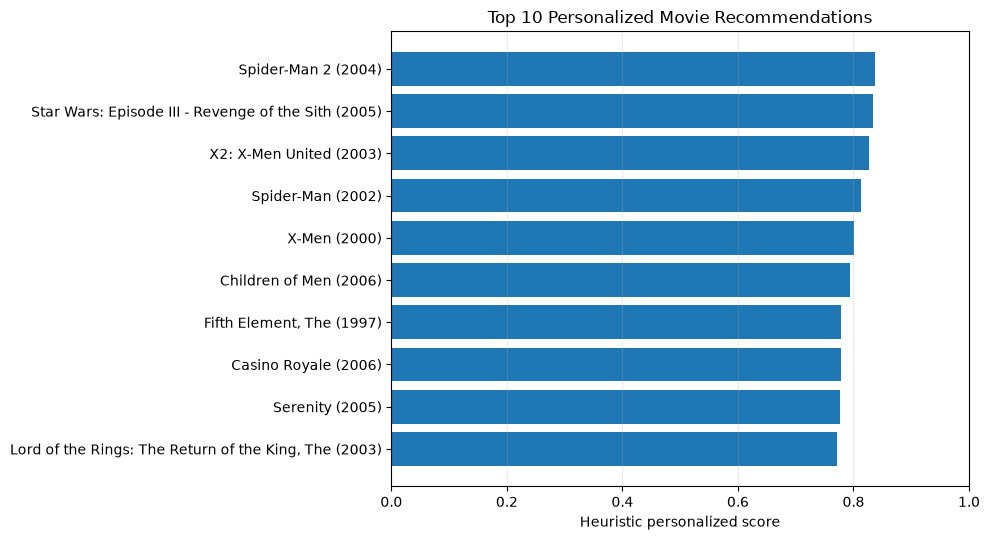

In [34]:
# Visual comparison of final recommendation relevance scores
plot_recs = top10_final.sort_values("personalized_score")
plt.figure(figsize=(10, 5.5))
plt.barh(plot_recs["title"], plot_recs["personalized_score"])
plt.xlabel("Heuristic personalized score")
plt.title("Top 10 Personalized Movie Recommendations")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### 6.5 Results, Measurable Justifications and Limitations

The table and chart above are **generated dynamically** from the current algorithm rather than copied from the previous heuristic model. A recommendation's measurable explanation is its **shared genres** with the user's favorites, its **cosine similarity**, its **number of training ratings**, and its **Bayesian weighted rating**. No unsupported claims about matching cinematic tone or narrative themes are needed.

**Interpretation:** We expect high-ranked films to be reasonably well reviewed, share relevant genres (especially Action, Adventure and Sci-Fi), and be relatively close in release period to the examples. These features are proxies; they do not guarantee individual enjoyment. Genre-only content signals may not distinguish superhero movies from other action films, and 3 favorite titles provide very limited preference evidence.

**Methodological limitations:** The scores are not predicted user ratings; the 65/25/10 weights, 100-rating filter, 3.5 rating floor and release-year restriction are heuristic. The candidate list contains only films rated before 2008 to preserve the evaluation boundary. Consequently, movies debuting in 2008 cannot be suggested from the training ratings. We deliberately avoid training on held-out ratings. A production model should be updated with later observed data, while a rigorous offline comparison should keep evaluation data held out.

**Further work:** Collect explicit user scores and fold in a user vector for movies known to MF; separately assess recommendation precision and diversity on an appropriate validation set. More informative metadata, such as tags, plot embeddings or cast, can improve specificity.

## 7. Final Project Summary

The project answers all six tasks using the MovieLens 10M dataset. It loads and merges the ratings, studies first-to-last-year genre averages, evaluates sample-size sensitivity and uncertainty, trains a regularized matrix-factorization model with stochastic gradient descent (an efficient per-observation form of gradient descent), reports **MSE and RMSE** on a temporal holdout, and creates recommendations for new users.

**Important distinctions:** The temporal holdout has substantial cold-start coverage; overall improvement over a constant mean does **not** prove that latent factors alone caused the improvement. The bias ablation below the main evaluation separates the incremental effect of latent factors. Q6 uses genre metadata, cosine similarity, rating quality and release-year preference, **not a fitted new-user MF vector**. It does not train on future/test ratings.

**Limitations:** Early years and partial 2009 coverage make extreme-year comparisons sensitive to data support; nominal confidence intervals rely on independence assumptions; thresholds and ranking weights were chosen heuristically without a validation set. Item availability is limited by the pre-2008 training cutoff.

**Possible extensions:** Proper nested time-based validation and hyperparameter tuning; movie metadata and richer text features; MF fold-in after explicit feedback; ranking metrics and recommendation diversity.